# Fase 4a — Regresión funcional función a función (modelo de referencia)

**Qué pide el enunciado.** La cabeza lineal de la red funcional, con el decodificador FPCA, debe **equivaler a una regresión funcional función a función de rango bajo**

$$\hat y(t)=\alpha(t)+\int \beta(s,t)\,x(s)\,ds,\qquad \beta(s,t)=\sum_k\sum_m w_k(s)\,B_{km}\,\psi_m(t),$$

y eso hay que **demostrarlo por escrito y verificarlo numéricamente** (diferencia máxima ≤ 1e‑4). Además la regresión funcional es uno de los modelos con que se compara la KAN (punto 4 del enunciado). Este notebook construye las piezas comunes que luego usa la red:

1. curvas en escala **√P** (la que pide el enunciado) sobre el dominio de la fase 1;
2. **partición** entrenamiento / prueba (por años y estaciones reservadas);
3. **matriz de Gram** W = ∫φφᵀ por cuadratura de Gauss–Legendre (exacta para B‑splines);
4. **FPCA** de las curvas de estación, **solo con entrenamiento**, con la varianza explicada;
5. la **regresión funcional** penalizada (rugosidad en s), con λ por validación cruzada dejando un año fuera;
6. la **demostración y la verificación numérica** de la equivalencia con la cabeza lineal;
7. métricas frente a dos referencias: el **satélite sin corregir** y la **climatología** (μ(t)).

> **Emparejamiento provisional.** Falta la tabla `STATION_ID → lat, lon, altitud` (pregunta 1 al profesor), así que todavía no se puede tomar el píxel de cada estación. Aquí la entrada x(s) de cada estación‑año es la **curva satelital promedio de los píxeles de tierra del dominio** en ese año. Todo el código recibe una tabla de pares (estación, año) → curva satelital, de modo que al llegar las coordenadas basta cambiar la función `curva_satelite_de(estacion, anio)` y volver a correr. Con la entrada regional el modelo solo puede aprender la variación **entre años** común a toda la región; las conclusiones de este notebook son sobre el método, no sobre la calidad final.

In [1]:
from pathlib import Path
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import minimize

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
ROOT = Path.cwd(); F1 = ROOT / "fda_fase1"; F2 = ROOT / "fda_fase2"; E0 = ROOT / "eda_fase0"
OUT = ROOT / "fda_fase4_regresion"; OUT.mkdir(exist_ok=True)
espec = json.load(open(F1 / "base_especificacion.json"))
RANGO, ORDEN = tuple(espec["rango"]), espec["orden"]
K_Y, K_X = espec["K_estaciones"], espec["K_satelite"]     # 6 y 11, elegidos por VC en la fase 1
AÑOS_DEFECTUOSOS = [1985, 1988, 2000]                      # satélite con déficit (notebook 02)
print(f"Dominio {RANGO}, orden {ORDEN}, K estación = {K_Y}, K satélite = {K_X}")

Dominio (1, 365), orden 4, K estación = 6, K satélite = 11


## 1. Bases B‑spline y matrices de Gram

Se reusa la base programada en la fase 1 (Cox–de Boor). La **matriz de Gram** de una base es W = ∫φ(t)φ(t)ᵀdt. En el producto de dos B‑splines cúbicos cada tramo entre nodos es un polinomio de grado 6, así que **Gauss–Legendre con 4 puntos por tramo es exacta** (integra exactamente hasta grado 7). Con W se calculan todas las integrales del modelo sin aproximarlas por sumas:

- ∫x(s)y(s)ds = c_xᵀ W c_y,
- la norma L² de una curva ‖f‖² = cᵀWc.

También se necesita la matriz de **rugosidad** R = ∫φ''φ''ᵀ (segunda derivada), para penalizar que β(s,t) oscile en s. Allí cada tramo es grado 2, también exacto.

In [2]:
def nodos(rango, K, orden=ORDEN):
    a, b = rango; inter = np.linspace(a, b, K - orden + 2)[1:-1]
    return np.r_[[a] * orden, inter, [b] * orden]

def base_bspline(t, rango, K, orden=ORDEN):
    t = np.asarray(t, float); tau = nodos(rango, K, orden)
    B = np.zeros((len(t), len(tau) - 1))
    for j in range(len(tau) - 1):
        B[:, j] = (t >= tau[j]) & (t < tau[j + 1])
    ultimo = np.max(np.flatnonzero(tau[:-1] < tau[1:])); B[t == rango[1], ultimo] = 1
    for m in range(2, orden + 1):
        Bn = np.zeros((len(t), len(tau) - m))
        for j in range(len(tau) - m):
            d1, d2 = tau[j + m - 1] - tau[j], tau[j + m] - tau[j + 1]
            izq = (t - tau[j]) / d1 * B[:, j] if d1 > 0 else 0
            der = (tau[j + m] - t) / d2 * B[:, j + 1] if d2 > 0 else 0
            Bn[:, j] = izq + der
        B = Bn
    return B

def d2_bspline(t, rango, K, h=1e-3):
    # 2.ª derivada por diferencias centrales de la base (polinomio cúbico por tramo → error ~h²)
    return (base_bspline(np.clip(t + h, *rango), rango, K) - 2 * base_bspline(t, rango, K)
            + base_bspline(np.clip(t - h, *rango), rango, K)) / h**2

def puntos_gauss(rango, K, n=4):
    # nodos y pesos de Gauss–Legendre en cada tramo entre nodos interiores
    tau = np.unique(nodos(rango, K)); g, w = np.polynomial.legendre.leggauss(n)
    T, Wt = [], []
    for a, b in zip(tau[:-1], tau[1:]):
        T.append((b - a) / 2 * g + (a + b) / 2); Wt.append((b - a) / 2 * w)
    return np.concatenate(T), np.concatenate(Wt)

def gram(rango, K, deriv=0):
    t, w = puntos_gauss(rango, K)
    P = base_bspline(t, rango, K) if deriv == 0 else d2_bspline(t, rango, K)
    return (P * w[:, None]).T @ P

W_X, W_Y = gram(RANGO, K_X), gram(RANGO, K_Y)
R_X = gram(RANGO, K_X, deriv=2)

# Verificaciones: (1) suma de W = longitud del dominio (partición de la unidad);
# (2) frente a una regla del trapecio muy fina; (3) simetría y definida positiva
tf = np.linspace(*RANGO, 200001); Pf = base_bspline(tf, RANGO, K_X)
W_trap = np.trapezoid(Pf[:, :, None] * Pf[:, None, :], tf, axis=0)
print(f"suma(W_X) = {W_X.sum():.6f} (debe ser {RANGO[1]-RANGO[0]})")
print(f"max |W_X(Gauss) − W_X(trapecio fino)| = {np.abs(W_X - W_trap).max():.2e}")
print(f"W_X simétrica: {np.allclose(W_X, W_X.T)} | autovalor mínimo = {np.linalg.eigvalsh(W_X).min():.3f} > 0")

suma(W_X) = 364.000000 (debe ser 364)
max |W_X(Gauss) − W_X(trapecio fino)| = 3.64e-08
W_X simétrica: True | autovalor mínimo = 1.581 > 0


## 2. Curvas en escala √P

El enunciado pide modelar sobre √P o log(1+P) y devolver la reconstrucción en mm **no negativa**. Se usa **√P**: estabiliza la varianza (que crece con la media) sin tener que elegir la constante del logaritmo, y volver a mm es elevar al cuadrado lo que se recorta en 0.

Como se decidió en la fase 1 (§1), la raíz se aplica **sobre la curva ya suavizada en mm/día**, no sobre la lluvia diaria. La lluvia diaria es intermitente (muchos ceros) y la raíz de cada día subestima mucho la tasa media: con las estaciones, (promedio de √P diario)² da 1.8 mm/día frente a 5.4 mm/día reales. Así que, para cada curva f(t) en mm/día de la fase 1, se evalúa √max(f(t), 0) en los 365 días y se proyecta sobre la misma base por mínimos cuadrados.

- **Estaciones:** los 4 426 pares estación‑año válidos, con sus coeficientes de la fase 1 (K = 6).
- **Satélite:** para la entrada provisional, el **promedio areal en mm/día** de los píxeles de tierra de cada año (el promedio de lluvia de una región sí tiene sentido físico en mm), suavizado con K = 11 y luego llevado a √.

In [3]:
dias = np.arange(1, 366); Phi_y = base_bspline(dias, RANGO, K_Y); Phi_x365 = base_bspline(dias, RANGO, K_X)

def a_raiz(C_mm, Phi):
    # curvas en mm/día (coeficientes) → coeficientes de √max(f, 0) en la misma base
    F = np.clip(C_mm @ Phi.T, 0, None)
    return np.linalg.solve(Phi.T @ Phi, Phi.T @ np.sqrt(F).T).T

ce = np.load(F1 / "coeficientes_estaciones.npz")
C_y_mm, est_id, est_anio = ce["coef"], ce["station_id"], ce["anio"]
C_y = a_raiz(C_y_mm, Phi_y)
err_proy = np.abs((C_y @ Phi_y.T) - np.sqrt(np.clip(C_y_mm @ Phi_y.T, 0, None))).max(1)
cuenca = pd.read_csv(E0 / "pares_estacion_anio_validos_preliminar.csv").set_index(["STATION_ID", "YEAR"]).cuenca
cuenca = np.array([cuenca.get((s, a), "?") for s, a in zip(est_id, est_anio)])

sat = pd.read_csv(F1 / "curvas_satelite_mm.csv.gz")
tierra = pd.read_csv(F2 / "coef_satelite_tierra.csv.gz", usecols=["anio", "fila", "col"])
sat = sat.merge(tierra, on=["anio", "fila", "col"])
cols_t = [c for c in sat.columns if c.startswith("t")]; t_sat = np.array([float(c[1:]) for c in cols_t])
X_reg_mm = sat.groupby("anio")[cols_t].mean()                         # promedio areal (mm/día)
Phi_x = base_bspline(t_sat, RANGO, K_X)
C_x_mm_anio = pd.DataFrame(np.linalg.solve(Phi_x.T @ Phi_x, Phi_x.T @ X_reg_mm.to_numpy().T).T, index=X_reg_mm.index)
C_x_anio = pd.DataFrame(a_raiz(C_x_mm_anio.to_numpy(), Phi_x365), index=X_reg_mm.index)
print(f"Estaciones: {len(C_y)} curvas, {len(np.unique(est_id))} estaciones, {est_anio.min()}–{est_anio.max()}")
print(f"Error de la proyección de √f sobre la base (mediana del máximo por curva): {np.median(err_proy):.3f} √(mm/día)")
print(f"Satélite: {sat.groupby('anio').size().iloc[0]} píxeles de tierra por año, {X_reg_mm.index.min()}–{X_reg_mm.index.max()}")
print(f"Lluvia media — estaciones: {np.clip(C_y_mm @ Phi_y.T, 0, None).mean()*365:.0f} mm/año | "
      f"satélite (promedio areal): {X_reg_mm.to_numpy().mean()*365:.0f} mm/año")

def curva_satelite_de(estacion, anio, escala="raiz"):
    # PROVISIONAL: la misma curva regional para todas las estaciones del año.
    # Con coordenadas: devolver los coeficientes del píxel (o del promedio 3x3) de la estación.
    return (C_x_anio if escala == "raiz" else C_x_mm_anio).loc[anio].to_numpy()

Estaciones: 4426 curvas, 238 estaciones, 1981–2003
Error de la proyección de √f sobre la base (mediana del máximo por curva): 0.420 √(mm/día)
Satélite: 1353 píxeles de tierra por año, 1981–2012
Lluvia media — estaciones: 1992 mm/año | satélite (promedio areal): 3388 mm/año


## 3. Partición entrenamiento / prueba

Todo lo que se **ajusta** (media, FPCA, β, λ) usa solo entrenamiento. Propuesta (pregunta 12 al profesor):

- **Años de prueba:** 1999, 2001, 2002 y 2003 (los últimos años con estaciones). **2000 se excluye** de todo porque el satélite viene defectuoso; 1985 y 1988 también se excluyen del entrenamiento por la misma razón (se reportan aparte).
- **Estaciones reservadas:** el 20 % de las estaciones (semilla 42), fuera del entrenamiento en todos los años. Permite medir si el modelo sirve en sitios que no vio.

Así quedan tres conjuntos de evaluación: años nuevos con estaciones vistas, años vistos con estaciones nuevas, y ambos nuevos.

In [4]:
rng = np.random.default_rng(42)
estaciones = np.unique(est_id)
reservadas = set(rng.choice(estaciones, size=int(round(.2 * len(estaciones))), replace=False))
AÑOS_PRUEBA = [1999, 2001, 2002, 2003]
es_res = np.isin(est_id, list(reservadas)); es_def = np.isin(est_anio, AÑOS_DEFECTUOSOS)
es_prueba_a = np.isin(est_anio, AÑOS_PRUEBA)
conj = np.where(es_def, "excluido (satélite defectuoso)",
       np.where(~es_prueba_a & ~es_res, "entrenamiento",
       np.where(es_prueba_a & ~es_res, "prueba: años nuevos",
       np.where(~es_prueba_a & es_res, "prueba: estaciones nuevas", "prueba: ambos nuevos"))))
tabla = pd.crosstab(conj, cuenca, margins=True, margins_name="total")
tabla.to_csv(OUT / "particion_conteos.csv"); display(tabla)
tr = conj == "entrenamiento"
print("Años de entrenamiento:", sorted(set(est_anio[tr])))
pd.DataFrame({"STATION_ID": est_id, "YEAR": est_anio, "conjunto": conj}).to_csv(OUT / "particion.csv", index=False)

col_0,Cauca,Pacífico,total
row_0,,,
entrenamiento,2209,341,2550
excluido (satélite defectuoso),495,76,571
prueba: ambos nuevos,131,10,141
prueba: años nuevos,453,53,506
prueba: estaciones nuevas,568,90,658
total,3856,570,4426


Años de entrenamiento: [np.int64(1981), np.int64(1982), np.int64(1983), np.int64(1984), np.int64(1986), np.int64(1987), np.int64(1989), np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998)]


## 4. FPCA de las curvas de estación (solo entrenamiento)

Con las curvas en la base, y(t) = c_yᵀφ(t). La media es μ(t) = c̄ᵀφ(t). La covarianza es v(s,t) = φ(s)ᵀΣ_cφ(t), con Σ_c la covarianza de los coeficientes. Las funciones propias ψ resuelven ∫v(s,t)ψ(s)ds = ρψ(t). Escribiendo ψ = eᵀφ, el problema queda en matrices:

$$\Sigma_c W\,e=\rho\,e \;\Longleftrightarrow\; (W^{1/2}\Sigma_cW^{1/2})\,u=\rho\,u,\quad e=W^{-1/2}u .$$

Así las ψ_m son **ortonormales en L²** (eᵀWe = 1) y el puntaje de una curva es s_m = ∫(y−μ)ψ_m = e_mᵀW(c_y − c̄). M se elige con el criterio de varianza acumulada ≥ 90 %, y se verifica contra `scikit-fda`.

Varianza explicada: [71.1 11.1  6.4  4.6  3.7  3. ] 
Acumulada: [ 71.1  82.2  88.6  93.3  97.  100. ] 
→ M = 4
ψ ortonormales (EᵀWE = I): True


scikit-fda — varianza explicada %: [71.1 11.1  6.4  4.6]
max |ψ_propia − ψ_skfda| (salvo signo): 0.0


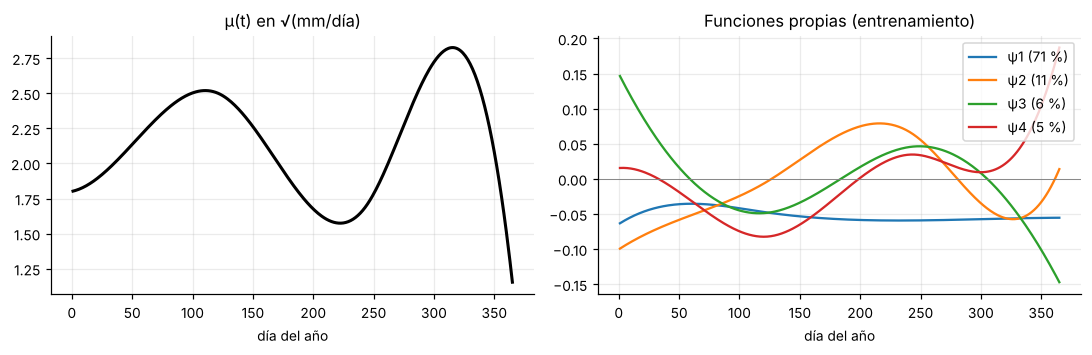

In [5]:
Cy_tr = C_y[tr]; c_bar = Cy_tr.mean(0)
Sig = np.cov(Cy_tr, rowvar=False)
ev, U = np.linalg.eigh(W_Y); W_Y_h = U @ np.diag(np.sqrt(ev)) @ U.T; W_Y_mh = U @ np.diag(1/np.sqrt(ev)) @ U.T
rho, Uv = np.linalg.eigh(W_Y_h @ Sig @ W_Y_h); o = np.argsort(rho)[::-1]; rho, Uv = rho[o], Uv[:, o]
E = W_Y_mh @ Uv                                             # columnas: coeficientes de ψ_m
var_exp = rho / rho.sum(); acum = np.cumsum(var_exp)
M = int(np.searchsorted(acum, .90) + 1)
print("Varianza explicada:", np.round(100 * var_exp, 1), "\nAcumulada:", np.round(100 * acum, 1), f"\n→ M = {M}")
print(f"ψ ortonormales (EᵀWE = I): {np.allclose(E.T @ W_Y @ E, np.eye(K_Y))}")
pd.DataFrame({"componente": np.arange(1, K_Y + 1), "var_explicada_%": 100 * var_exp, "acumulada_%": 100 * acum}).to_csv(OUT / "fpca_varianza.csv", index=False)

try:   # verificación con scikit-fda (mismo espacio de B-splines)
    import skfda
    from skfda.representation.basis import BSplineBasis
    from skfda.preprocessing.dim_reduction import FPCA
    fd = skfda.FDataBasis(BSplineBasis(domain_range=RANGO, n_basis=K_Y, order=ORDEN), Cy_tr)
    fp = FPCA(n_components=M).fit(fd)
    print("scikit-fda — varianza explicada %:", np.round(100 * fp.explained_variance_ratio_, 1))
    g = np.linspace(*RANGO, 365); propio = (base_bspline(g, RANGO, K_Y) @ E[:, :M])
    lib = fp.components_(g)[..., 0].T
    print("max |ψ_propia − ψ_skfda| (salvo signo):", np.abs(np.abs(propio) - np.abs(lib)).max().round(5))
except Exception as e:
    print("scikit-fda no disponible:", e)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].plot(dias, Phi_y @ c_bar, "k", lw=2); ax[0].set(title="μ(t) en √(mm/día)", xlabel="día del año")
for m in range(M): ax[1].plot(dias, Phi_y @ E[:, m], label=f"ψ{m+1} ({100*var_exp[m]:.0f} %)")
ax[1].axhline(0, c="gray", lw=.6); ax[1].legend(); ax[1].set(title="Funciones propias (entrenamiento)", xlabel="día del año")
plt.tight_layout(); plt.savefig(OUT / "fpca.png", dpi=130); plt.show()

## 5. Regresión funcional función a función

**Modelo.** Con x_i(s) la curva satelital (en √P) y y_i(t) la curva de la estación:

$$y_i(t)=\alpha(t)+\int\beta(s,t)\,x_i(s)\,ds+\varepsilon_i(t).$$

**Representación de rango bajo.** Se expande β en la base satelital en s y en las M funciones propias en t: β(s,t) = Σ_j Σ_m b_jm φ_j(s) ψ_m(t). Entonces

$$\int\beta(s,t)x_i(s)ds=\sum_m\big(c_{x,i}^\top W_X\, b_m\big)\,\psi_m(t),$$

y proyectando y_i − μ sobre ψ_m (ortonormales) el problema se reduce a M regresiones lineales de los **puntajes** s_im sobre z_i = W_X c_{x,i}:

$$s_{im}=a_m+z_i^\top b_m+e_{im}.$$

**Pérdida y penalización.** Como las ψ son ortonormales, la pérdida L² funcional del enunciado, (ĉ−c)ᵀW_Y(ĉ−c), es igual a la suma de errores cuadrados de los puntajes más una constante que no depende de β. La rugosidad en s, ∫∫(∂²β/∂s²)² ds dt, es Σ_m b_mᵀ R_X b_m. La rugosidad sola **no encoge** la parte de β que es lineal en s (su segunda derivada es 0), así que aunque λ crezca el modelo nunca llega a "no usar el satélite" (β = 0). Por eso se suma un término pequeño de tamaño, δ∫∫β² = δ Σ_m b_mᵀ W_X b_m, con δ fijo: P = R_X + δW_X. Así cada b_m tiene solución cerrada:

$$\hat b_m=(Z_c^\top Z_c+\lambda P)^{-1}Z_c^\top s_{\cdot m},\qquad Z_c = Z-\bar Z .$$

Con λ → ∞ el modelo se vuelve la climatología μ(t), así que la validación cruzada puede decidir si la entrada satelital ayuda o no.

**λ** se elige por validación cruzada **dejando un año fuera** (no una curva): las estaciones del mismo año comparten la entrada x, así que dejar curvas sueltas fuera filtraría información.

λ óptimo = 1.78e+10 | error VC = 245.0624 | VC solo media (β=0) = 247.7798
λ óptimo en el borde de la rejilla: False


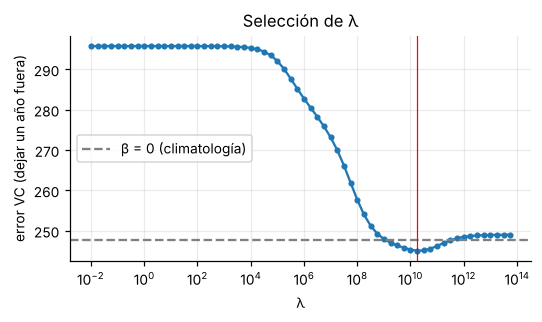

In [6]:
DELTA = 1e-2 * np.trace(R_X) / np.trace(W_X)          # término de tamaño: pequeño frente a la rugosidad
P_X = R_X + DELTA * W_X

def puntajes(C):            # s = (C − c̄) W_Y E_M
    return (C - c_bar) @ W_Y @ E[:, :M]

Z_all = np.vstack([W_X @ curva_satelite_de(s, a) for s, a in zip(est_id, est_anio)])   # z_i = W_X c_x,i
S_all = puntajes(C_y)

def ajustar_fof(Z, S, lam):
    zb, sb = Z.mean(0), S.mean(0); Zc = Z - zb
    Bm = np.linalg.solve(Zc.T @ Zc + lam * P_X, Zc.T @ (S - sb))   # K_X x M
    a = sb - zb @ Bm
    return a, Bm

def predecir_puntajes(Z, a, Bm): return a + Z @ Bm

def error_L2(S_hat, S):     # ∫(ŷ−y_proy)² en √ escala, promedio por curva
    return ((S_hat - S) ** 2).sum(1).mean()

lams = 10.0 ** np.arange(-2, 14, .25)
anios_tr = np.array(sorted(set(est_anio[tr])))
cv = []
for lam in lams:
    err = []
    for a_out in anios_tr:
        m_in, m_out = tr & (est_anio != a_out), tr & (est_anio == a_out)
        a, Bm = ajustar_fof(Z_all[m_in], S_all[m_in], lam)
        err.append(((predecir_puntajes(Z_all[m_out], a, Bm) - S_all[m_out]) ** 2).sum(1))
    cv.append(np.concatenate(err).mean())
cv = np.array(cv); lam_opt = lams[np.argmin(cv)]
# referencia: modelo solo con la media (β = 0)
cv_media = np.mean([((S_all[tr & (est_anio == a)] - S_all[tr & (est_anio != a)].mean(0)) ** 2).sum(1).mean() for a in anios_tr])
print(f"λ óptimo = {lam_opt:.3g} | error VC = {cv.min():.4f} | VC solo media (β=0) = {cv_media:.4f}")
print(f"λ óptimo en el borde de la rejilla: {lam_opt == lams[-1]}")
a_hat, B_hat = ajustar_fof(Z_all[tr], S_all[tr], lam_opt)

fig, ax = plt.subplots(figsize=(5, 3))
ax.semilogx(lams, cv, "o-", ms=3); ax.axhline(cv_media, c="gray", ls="--", label="β = 0 (climatología)")
ax.axvline(lam_opt, c="r", lw=.8); ax.set(xlabel="λ", ylabel="error VC (dejar un año fuera)", title="Selección de λ"); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "seleccion_lambda.png", dpi=130); plt.show()
pd.DataFrame({"lambda": lams, "error_vc": cv}).to_csv(OUT / "seleccion_lambda.csv", index=False)

### La superficie β(s,t)

β(s,t) = φ_X(s)ᵀ B̂ E_Mᵀ φ_Y(t). El intercepto α(t) es la curva que se predeciría con un satélite en 0 todo el año, así que por sí solo no tiene sentido físico; con el satélite medio la predicción es exactamente μ(t). Se lee así: el valor en (s,t) dice cuánto sube la curva de la estación el día t cuando la curva satelital sube en el día s. Un modelo que solo corrigiera el sesgo día a día tendría β concentrada en la diagonal s = t.

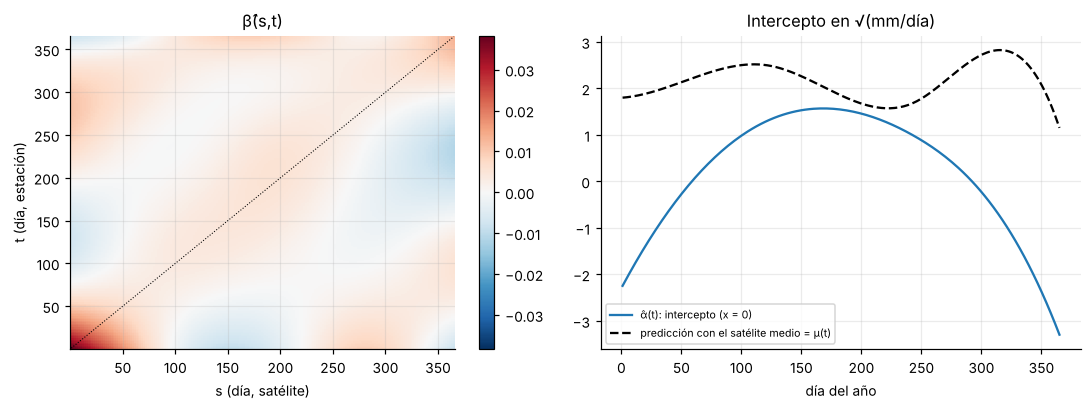

In [7]:
g = np.linspace(*RANGO, 200)
beta = base_bspline(g, RANGO, K_X) @ B_hat @ E[:, :M].T @ base_bspline(g, RANGO, K_Y).T   # (s, t)
alpha = base_bspline(g, RANGO, K_Y) @ (c_bar + E[:, :M] @ a_hat)
np.save(OUT / "beta_superficie.npy", beta)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
v = np.abs(beta).max()
im = ax[0].pcolormesh(g, g, beta.T, cmap="RdBu_r", vmin=-v, vmax=v, shading="auto")
ax[0].plot(RANGO, RANGO, "k:", lw=.7); ax[0].set(xlabel="s (día, satélite)", ylabel="t (día, estación)", title="β̂(s,t)")
plt.colorbar(im, ax=ax[0])
ax[1].plot(g, alpha, label="α̂(t): intercepto (x = 0)")
ax[1].plot(g, base_bspline(g, RANGO, K_Y) @ c_bar, "k--", label="predicción con el satélite medio = μ(t)")
ax[1].set(title="Intercepto en √(mm/día)", xlabel="día del año"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "beta_alpha.png", dpi=130); plt.show()

## 6. Equivalencia con la cabeza lineal de la red funcional

**Red funcional** (enunciado, sección del modelo):

- *Codificador:* K_enc neuronas funcionales z_k = ∫w_k(s)x(s)ds con w_k(s) = a_kᵀφ_X(s). En matrices **z = A W_X c_x** (A es K_enc × K_X).
- *Cabeza lineal:* puntajes ŝ = d + Bᵀz (B es K_enc × M).
- *Decodificador FPCA congelado:* ŷ(t) = μ(t) + Σ_m ŝ_m ψ_m(t).

**Demostración.** Sustituyendo:

$$\hat y(t)=\mu(t)+\sum_m d_m\psi_m(t)+\sum_m\sum_k B_{km}\Big(\int w_k(s)x(s)ds\Big)\psi_m(t)
=\alpha(t)+\int\Big[\sum_k\sum_m w_k(s)B_{km}\psi_m(t)\Big]x(s)\,ds,$$

con α(t) = μ(t) + Σ d_mψ_m(t). El corchete es exactamente β(s,t) = Σ_kΣ_m w_k(s)B_kmψ_m(t): la red con cabeza lineal **es** una regresión funcional función a función, de rango ≤ min(K_enc, M). Además la penalización de rugosidad de la red sobre las w_k, combinada con B, es la de β: si A = I (una neurona por función de la base), b_m = columna m de B y Σ_m b_mᵀR_Xb_m = ∫∫(∂²_sβ)². Por tanto, entrenar la red lineal con esa pérdida tiene **el mismo óptimo** que la regresión del punto 5. ∎

**Verificación numérica**, dos pruebas:

1. **Identidad.** Con pesos cualesquiera (A, B, d), la salida calculada *como red* (z = AW_Xc_x → ŝ → ŷ) y la calculada *integrando la superficie* β(s,t) por cuadratura sobre una rejilla fina deben coincidir.
2. **Entrenamiento.** Se entrena la red lineal (A = I) por gradiente (L‑BFGS) con la pérdida L² funcional + rugosidad, partiendo de ceros, y se comparan sus predicciones con las de la solución cerrada del punto 5.

Criterio del enunciado: diferencia máxima ≤ 1e‑4.

In [8]:
# --- Prueba 1: identidad red ↔ superficie β, con pesos aleatorios
rng = np.random.default_rng(0); K_ENC = 8
A = rng.normal(size=(K_ENC, K_X)) / K_X; Bh = rng.normal(size=(K_ENC, M)); d = rng.normal(size=M)
idx = rng.choice(len(C_y), 200, replace=False)
Cx = np.vstack([curva_satelite_de(est_id[i], est_anio[i]) for i in idx])

t_eval = np.linspace(*RANGO, 365)
psi = base_bspline(t_eval, RANGO, K_Y) @ E[:, :M]; mu = base_bspline(t_eval, RANGO, K_Y) @ c_bar
y_red = mu + (d + (Cx @ W_X.T @ A.T) @ Bh) @ psi.T                    # vía red

sq, wq = puntos_gauss(RANGO, K_X, n=8)                                 # cuadratura fina en s
w_k = base_bspline(sq, RANGO, K_X) @ A.T                               # w_k(s)
beta_q = w_k @ Bh @ psi.T                                              # β(s_q, t)
x_q = Cx @ base_bspline(sq, RANGO, K_X).T                              # x_i(s_q)
y_beta = mu + d @ psi.T + (x_q * wq) @ beta_q                         # α(t) + ∫β(s,t)x(s)ds
dif1 = np.abs(y_red - y_beta).max()
print(f"Prueba 1 — max |ŷ_red − ŷ_β| = {dif1:.2e}  →  {'CUMPLE' if dif1 <= 1e-4 else 'NO cumple'} (≤ 1e-4)")

# --- Prueba 2: red lineal entrenada por gradiente vs solución cerrada
# Pérdida de la red: (1/n) Σ ‖ŝ_i − s_i‖² + (λ/n) Σ_m b_mᵀ P_X b_m, con ŝ = d + Zᵀ... (A = I).
# Para que el gradiente converja bien se centran y escalan las entradas (equivale a una
# normalización de capa fija); al final se deshace el cambio de variables.
Ztr, Str = Z_all[tr], S_all[tr]; n = len(Ztr)
zm, zs = Ztr.mean(0), Ztr.std(0); Zt = (Ztr - zm) / zs
P_t = P_X / np.outer(zs, zs)                               # penalización en las variables escaladas
def perdida(theta):
    Th = theta[:K_X * M].reshape(K_X, M); dd = theta[K_X * M:]
    r = dd + Zt @ Th - Str
    f = (r ** 2).sum() / n + lam_opt / n * np.einsum("jm,jk,km->", Th, P_t, Th)
    gT = 2 * Zt.T @ r / n + 2 * lam_opt / n * P_t @ Th; gd = 2 * r.sum(0) / n
    return f, np.r_[gT.ravel(), gd]
res = minimize(perdida, np.zeros(K_X * M + M), jac=True, method="L-BFGS-B",
               options={"maxiter": 100000, "maxfun": 100000, "ftol": 0, "gtol": 1e-13, "maxcor": 50})
Th = res.x[:K_X * M].reshape(K_X, M); B_gd = Th / zs[:, None]; d_gd = res.x[K_X * M:] - zm @ B_gd
y_cerrada = predecir_puntajes(Z_all, a_hat, B_hat) @ psi.T
y_gd = (d_gd + Z_all @ B_gd) @ psi.T
dif2 = np.abs(y_cerrada - y_gd).max()
print(f"Prueba 2 — L-BFGS: {res.nit} iteraciones ({res.message})")
print(f"           max |ŷ_red entrenada − ŷ_regresión| = {dif2:.2e}  →  {'CUMPLE' if dif2 <= 1e-4 else 'NO cumple'} (≤ 1e-4)")
pd.DataFrame({"prueba": ["identidad red-beta", "red entrenada vs cerrada"], "dif_max": [dif1, dif2]}).to_csv(OUT / "verificacion_equivalencia.csv", index=False)

Prueba 1 — max |ŷ_red − ŷ_β| = 1.51e-14  →  CUMPLE (≤ 1e-4)
Prueba 2 — L-BFGS: 37 iteraciones (CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH)
           max |ŷ_red entrenada − ŷ_regresión| = 1.32e-10  →  CUMPLE (≤ 1e-4)


## 7. Evaluación en mm

La reconstrucción vuelve a mm como ŷ_mm(t) = max(ŷ(t), 0)². Se reporta el **porcentaje de días recortados** (ŷ < 0 en √P). Se compara contra:

- **Satélite sin corregir:** la curva satelital de entrada, en mm (es la línea base del enunciado).
- **Climatología:** μ(t) de entrenamiento, igual para todos los años. Si la regresión no le gana, la entrada satelital no aporta información útil sobre la estación.

Métricas por curva (contra la curva suavizada de la estación de la fase 1, en mm/día):

- **L²** = √(∫(ŷ − y)²dt / 365), en mm/día;
- **sesgo del acumulado anual**, en %: (acumulado medio estimado / acumulado medio observado − 1) sobre el conjunto (el promedio de cocientes por curva se dispara en las estaciones secas);
- **KGE** (Kling–Gupta) sobre los 365 días;
- **error en la fecha del pico**, en días (circular).

Los intervalos de confianza del 95 % son bootstrap por año (1 000 remuestreos), porque las curvas del mismo año no son independientes.

In [9]:
Pt = base_bspline(dias, RANGO, K_Y); Px_d = base_bspline(dias, RANGO, K_X)
y_obs = np.clip(C_y_mm @ Pt.T, 0, None)                                    # estación suavizada fase 1 (mm/día)
raiz_fof = (predecir_puntajes(Z_all, a_hat, B_hat) @ E[:, :M].T + c_bar) @ Pt.T
recortados = (raiz_fof < 0).mean() * 100
pred = {"regresión funcional": np.clip(raiz_fof, 0, None) ** 2,
        "climatología μ(t)": np.tile(np.clip(c_bar @ Pt.T, 0, None) ** 2, (len(C_y), 1)),
        "satélite sin corregir": np.vstack([np.clip(curva_satelite_de(s, a, "mm") @ Px_d.T, 0, None)
                                            for s, a in zip(est_id, est_anio)])}
print(f"Días recortados a 0 en la reconstrucción: {recortados:.2f} %")

def kge(yh, y):
    r = np.array([np.corrcoef(a, b)[0, 1] if a.std() > 0 else 0 for a, b in zip(yh, y)])
    return 1 - np.sqrt((r - 1) ** 2 + (yh.std(1) / y.std(1) - 1) ** 2 + (yh.mean(1) / y.mean(1) - 1) ** 2)

def metricas(yh, y):
    dp = np.abs(yh.argmax(1) - y.argmax(1)); dp = np.minimum(dp, 365 - dp)
    return pd.DataFrame({"L2_mm_dia": np.sqrt(((yh - y) ** 2).mean(1)), "KGE": kge(yh, y),
                         "error_pico_dias": dp, "_tot_hat": yh.sum(1), "_tot_obs": y.sum(1)})

def resumir(df):            # medias por curva; sesgo del acumulado anual sobre el conjunto
    r = df[["L2_mm_dia", "KGE", "error_pico_dias"]].mean()
    r["sesgo_anual_%"] = 100 * (df._tot_hat.mean() / df._tot_obs.mean() - 1)
    return r

def boot_ic(df, anios, B=1000, seed=1):
    rng = np.random.default_rng(seed); u = np.unique(anios); grupos = {a: np.flatnonzero(anios == a) for a in u}
    med = []
    for _ in range(B):
        ii = np.concatenate([grupos[a] for a in rng.choice(u, len(u))])
        med.append(resumir(df.iloc[ii]))
    med = pd.DataFrame(med)
    return med.quantile(.025), med.quantile(.975)

filas = []
for c in ["entrenamiento", "prueba: años nuevos", "prueba: estaciones nuevas", "prueba: ambos nuevos"]:
    m = conj == c
    for nombre, yh in pred.items():
        dfm = metricas(yh[m], y_obs[m]); lo, hi = boot_ic(dfm, est_anio[m])
        r = resumir(dfm)
        for k in r.index:
            filas.append({"conjunto": c, "modelo": nombre, "métrica": k, "media": r[k], "IC95_inf": lo[k], "IC95_sup": hi[k]})
res_tab = pd.DataFrame(filas); res_tab.to_csv(OUT / "metricas.csv", index=False)
vista = res_tab.assign(valor=res_tab.apply(lambda r: f"{r.media:.2f} [{r.IC95_inf:.2f}, {r.IC95_sup:.2f}]", axis=1))
display(vista.pivot_table(index=["conjunto", "modelo"], columns="métrica", values="valor", aggfunc="first"))

Días recortados a 0 en la reconstrucción: 0.00 %


métrica                                                           KGE  \
conjunto                  modelo                                        
entrenamiento             climatología μ(t)         0.27 [0.21, 0.33]   
                          regresión funcional       0.30 [0.23, 0.36]   
                          satélite sin corregir  -0.73 [-0.93, -0.55]   
prueba: ambos nuevos      climatología μ(t)         0.34 [0.27, 0.42]   
                          regresión funcional       0.36 [0.30, 0.43]   
                          satélite sin corregir  -0.59 [-0.73, -0.45]   
prueba: años nuevos       climatología μ(t)         0.32 [0.20, 0.41]   
                          regresión funcional       0.34 [0.22, 0.42]   
                          satélite sin corregir  -0.66 [-0.93, -0.41]   
prueba: estaciones nuevas climatología μ(t)         0.31 [0.23, 0.36]   
                          regresión funcional       0.34 [0.26, 0.40]   
                          satélite sin corregir  -0.66 [-0.89, -0.47]   

métrica                                                  L2_mm_dia  \
conjunto                  modelo                                     
entrenamiento             climatología μ(t)      3.18 [3.06, 3.30]   
                          regresión funcional    3.10 [2.97, 3.23]   
                          satélite sin corregir  6.22 [5.92, 6.48]   
prueba: ambos nuevos      climatología μ(t)      2.77 [2.45, 3.19]   
                          regresión funcional    2.72 [2.45, 3.11]   
                          satélite sin corregir  5.71 [5.67, 5.75]   
prueba: años nuevos       climatología μ(t)      2.91 [2.39, 3.37]   
                          regresión funcional    2.85 [2.41, 3.26]   
                          satélite sin corregir  6.02 [5.81, 6.28]   
prueba: estaciones nuevas climatología μ(t)      2.68 [2.54, 2.83]   
                          regresión funcional    2.59 [2.45, 2.74]   
                          satélite sin corregir  5.60 [5.33, 5.86]   

métrica                                               error_pico_dias  \
conjunto                  modelo                                        
entrenamiento             climatología μ(t)      55.47 [44.75, 67.78]   
                          regresión funcional    55.04 [44.68, 67.14]   
                          satélite sin corregir  58.22 [49.58, 66.76]   
prueba: ambos nuevos      climatología μ(t)      37.83 [36.28, 39.92]   
                          regresión funcional    38.23 [36.41, 40.03]   
                          satélite sin corregir  45.52 [42.21, 48.77]   
prueba: años nuevos       climatología μ(t)      43.54 [35.06, 51.31]   
                          regresión funcional    43.88 [34.94, 52.07]   
                          satélite sin corregir  51.22 [40.84, 60.73]   
prueba: estaciones nuevas climatología μ(t)      46.99 [37.27, 57.80]   
                          regresión funcional    46.34 [36.92, 56.65]   
                          satélite sin corregir  54.00 [43.99, 64.77]   

métrica                                                   sesgo_anual_%  
conjunto                  modelo                                         
entrenamiento             climatología μ(t)      -13.32 [-17.34, -8.78]  
                          regresión funcional    -13.00 [-16.43, -9.27]  
                          satélite sin corregir    70.48 [62.95, 78.39]  
prueba: ambos nuevos      climatología μ(t)        -7.61 [-20.38, 4.13]  
                          regresión funcional      -5.83 [-13.07, 0.82]  
                          satélite sin corregir    81.39 [61.81, 95.52]  
prueba: años nuevos       climatología μ(t)        -8.86 [-22.41, 3.69]  
                          regresión funcional      -6.70 [-13.95, 3.32]  
                          satélite sin corregir   79.31 [59.24, 103.06]  
prueba: estaciones nuevas climatología μ(t)       -7.59 [-13.29, -1.53]  
                          regresión funcional     -7.31 [-12.31, -2.06]  
           

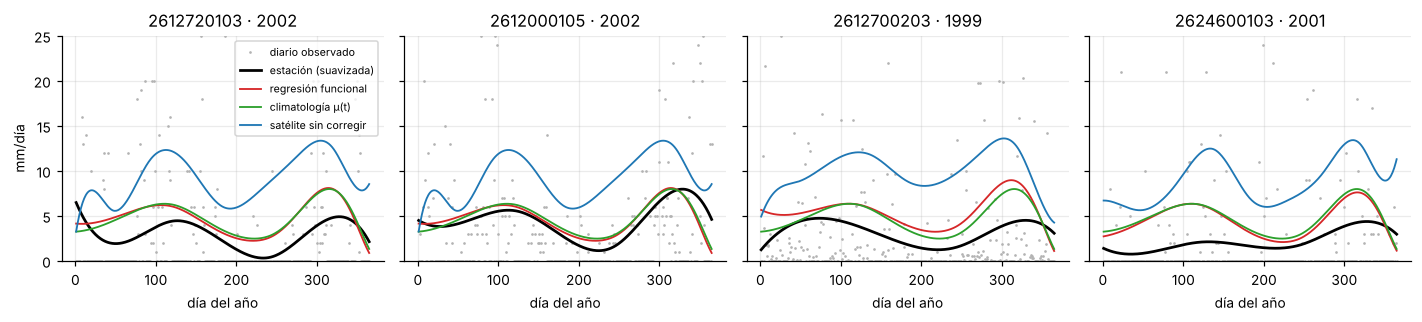

In [10]:
# Ejemplos: 4 curvas de prueba (años nuevos)
crudo = pd.read_csv(F1 / "curvas_estaciones_mm.csv.gz").set_index(["STATION_ID", "YEAR"])
Yraw = crudo.loc[list(zip(est_id, est_anio))].to_numpy(float)          # diario observado (mm), para la figura
m = np.flatnonzero(conj == "prueba: años nuevos"); ej = np.random.default_rng(3).choice(m, 4, replace=False)
fig, axs = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for ax, i in zip(axs, ej):
    ax.plot(dias, np.where(np.isnan(Yraw[i]), np.nan, Yraw[i]), ".", ms=1.5, c="0.7", label="diario observado")
    ax.plot(dias, y_obs[i], "k", lw=1.8, label="estación (suavizada)")
    for nombre, col in zip(pred, ["C3", "C2", "C0"]): ax.plot(dias, pred[nombre][i], c=col, lw=1.2, label=nombre)
    ax.set(title=f"{est_id[i]} · {est_anio[i]}", xlabel="día del año", ylim=(0, 25))
axs[0].set_ylabel("mm/día"); axs[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "ejemplos_prueba.png", dpi=130); plt.show()

## 8. Resultados con el emparejamiento provisional

- **Verificación de la equivalencia: cumple.** La identidad red ↔ superficie β da una diferencia de ~1e‑14 (solo error de redondeo) y la red lineal entrenada por gradiente llega a la solución cerrada con ~1e‑10, ambas muy por debajo de 1e‑4.
- **FPCA:** la primera función propia (≈71 % de la varianza) es casi constante: separa estaciones **más y menos lluviosas** en todo el año. Las siguientes mueven la forma bimodal (adelantan o atrasan las temporadas).
- **λ:** la VC elige una penalización muy fuerte. La regresión mejora a la climatología, pero poco (error VC 245 frente a 248). Es lo esperable: con la entrada regional hay **una sola curva satelital por año** (16 años de entrenamiento) y en la fase 2 el satélite casi no responde a ENSO, que es lo que más mueve los años en las estaciones. Además la entrada regional no puede explicar ψ₁ (lo lluviosa que es *cada* estación), que es el 71 % de la varianza.
- **Frente al satélite sin corregir**, la corrección sí es enorme: en los años de prueba el error L² baja de ≈6.0 a ≈2.9 mm/día y el sesgo del acumulado anual pasa de ≈+79 % a ≈−7 %. El sesgo negativo que queda (también en la climatología) viene de modelar en √: el cuadrado del promedio de las raíces subestima el promedio (desigualdad de Jensen). Se puede corregir sumando la varianza residual, ŷ_mm = ŷ² + σ̂²(t); queda como mejora.
- **Lectura correcta:** con la entrada regional, la regresión funcional casi coincide con la climatología. El modelo y su verificación ya están listos; lo que falta es la **información local**: el píxel de cada estación (y su altitud) debería permitir explicar ψ₁ y mejorar mucho sobre la climatología. Ese es el resultado que se reporta en la versión final.

## 9. Resumen

| Pieza | Estado |
|---|---|
| Matriz de Gram por cuadratura | Gauss–Legendre exacta, verificada contra trapecio fino |
| FPCA solo con entrenamiento | M y varianza explicada en `fpca_varianza.csv`, verificado con scikit‑fda |
| Regresión función a función | penalizada en s, λ por VC dejando un año fuera; β̂ en `beta_superficie.npy` |
| Equivalencia con la cabeza lineal | demostración escrita (punto 6) y dos verificaciones numéricas en `verificacion_equivalencia.csv` |
| Reconstrucción no negativa | √P → mm con recorte en 0, porcentaje recortado reportado |
| Métricas con IC bootstrap | `metricas.csv`, contra satélite sin corregir y climatología |

**Lo que falta para la versión final:** cambiar `curva_satelite_de` por el píxel de cada estación cuando lleguen las coordenadas (y añadir la altitud como covariable si se decide), confirmar la partición con el profesor y portar este notebook al archivo único de R. La KAN y el MLP usan exactamente las mismas piezas (z = AW_Xc_x, decodificador FPCA congelado, misma pérdida); solo cambia la cabeza.